
# Tarea Individual 2 – Estaciones de servicio vs. centros educativos en Seattle (WA, USA)

**Autor:** Romero Castillejo  |  **Datos:** [GitHub](https://github.com/Romero-Luis21/TareaIndividual2_Romero_Castillejo)

Flujo de trabajo:

1. Disolver los límites censales → límite único de Seattle.
2. Ubicar los centros educativos (OpenStreetMap).
3. Ubicar las estaciones de gasolina (OpenStreetMap).
4. Identificar qué estaciones están a **menos de 200 m** de algún centro educativo (mal ubicadas).
5. Proponer una reubicación para cada estación mal ubicada.
6. Graficar: bien ubicadas, mal ubicadas y ubicaciones propuestas.

> **Criterio usado:** una estación está *mal ubicada* si la distancia a su centro educativo más cercano es **menor a 200 m**
> (la regla es "distancia mínima de 200 m"). Todas las distancias se calculan en **metros** (EPSG:32610, UTM 10N),
> porque el shapefile original de Seattle suele venir en pies.



## 0. Instalaciones, librerías y parámetros



## 1. Disolver los límites censales → límite de Seattle

Se leen los *Census Tracts 2020* desde tu GitHub, se pasan a **metros** y se unen (`dissolve`) en **un solo polígono**
que representa a Seattle. Ese polígono será el área de trabajo para todo lo demás.


Área del límite disuelto: 216.5 km²

Tabla del límite disuelto (una sola geometría):


,geometry
0,"MULTIPOLYGON (((547410.876 5261554.553, 547407..."



CRS de trabajo:
<Projected CRS: EPSG:32610>
Name: WGS 84 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 126°W and 120°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - British Columbia (BC); Northwest Territories (NWT); Nunavut; Yukon. United States (USA) - Alaska (AK).
- bounds: (-126.0, 0.0, -120.0, 84.0)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich



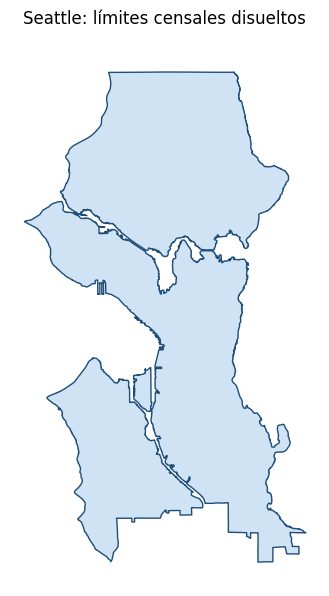


## 2. Ubicar los centros educativos de Seattle

Se descargan de OpenStreetMap (`amenity=school`) y se conservan solo los que caen dentro del límite de Seattle.
A continuación, cuántos son y una muestra de la tabla:


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   escuela   217 non-null    object  
 1   element   217 non-null    object  
 2   geometry  217 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 5.2+ KB

Tipo de elemento OSM (node/way/relation) vs. tipo de geometría:


col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


Primeras filas:


,escuela,element,geometry
0,Mapleleaf School,node,POINT (552925.436 5283350.335)
1,Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2,Epic Life Academy,node,POINT (549394.116 5283758.769)
3,Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4,Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


...

Estaciones distintas con buffer + sjoin : 25
Estaciones mal ubicadas por distancia   : 25



## 5. Propuesta de reubicación

Para cada estación mal ubicada se busca el **sitio candidato más cercano** que cumpla:

- está dentro de Seattle y sobre una **vía principal** (trunk / primary / secondary / tertiary de OSM), para que sea un lugar realista;
- está a **≥ 200 m (+ margen)** de todo centro educativo;
- está a **≥ 100 m** de las estaciones que se quedan y de las demás ubicaciones propuestas (evita amontonarlas).


25 reubicaciones propuestas. Todas cumplen >= 200 m.



,id,estacion,escuela_cercana,dist_escuela_actual_m,mover_m,geometry,dist_escuela_nueva_m
0,92,Shell,La Escuelita Bilingual School,0.8,248.0,POINT (553460.849 5267957.383),214.2
1,33,Shell,Northwest Montessori School,23.3,194.0,POINT (552477.088 5281476.208),220.3
2,62,Shell,Morningside Academy,36.6,279.0,POINT (551620.274 5273668.912),226.2
3,1,76,St. Nicholas School,75.1,282.0,POINT (550786.868 5274857.357),221.5
4,100,Space Age,Roxhill Elementary,91.2,144.0,POINT (546918.681 5264853.589),223.7
5,67,Shell,West Seattle Montessori School,94.5,112.0,POINT (546457.255 5267700.096),214.6
6,98,Shell,Lincoln High School,97.1,188.0,POINT (549411.264 5278981.205),216.7
7,86,Chevron,Lafayette Elementary School,100.3,110.0,POINT (546132.622 5270076.749),214.6
8,31,Chevron,Concordia Lutheran School,112.1,171.0,POINT (553275.064 5281317.63),224.1
9,20,Arco,Nova High School,124.0,109.0,POINT (552281.786 5272969.378),223.5



## 6. Gráfica final: bien ubicadas, mal ubicadas y ubicaciones propuestas

**Mapa estático:** el área naranja es la zona de 200 m alrededor de cada centro educativo; las estaciones en **verde**
están bien ubicadas, las **X rojas** están dentro de esa zona, y las **estrellas azules** son las ubicaciones propuestas
(la flecha une cada estación actual con su nueva ubicación).


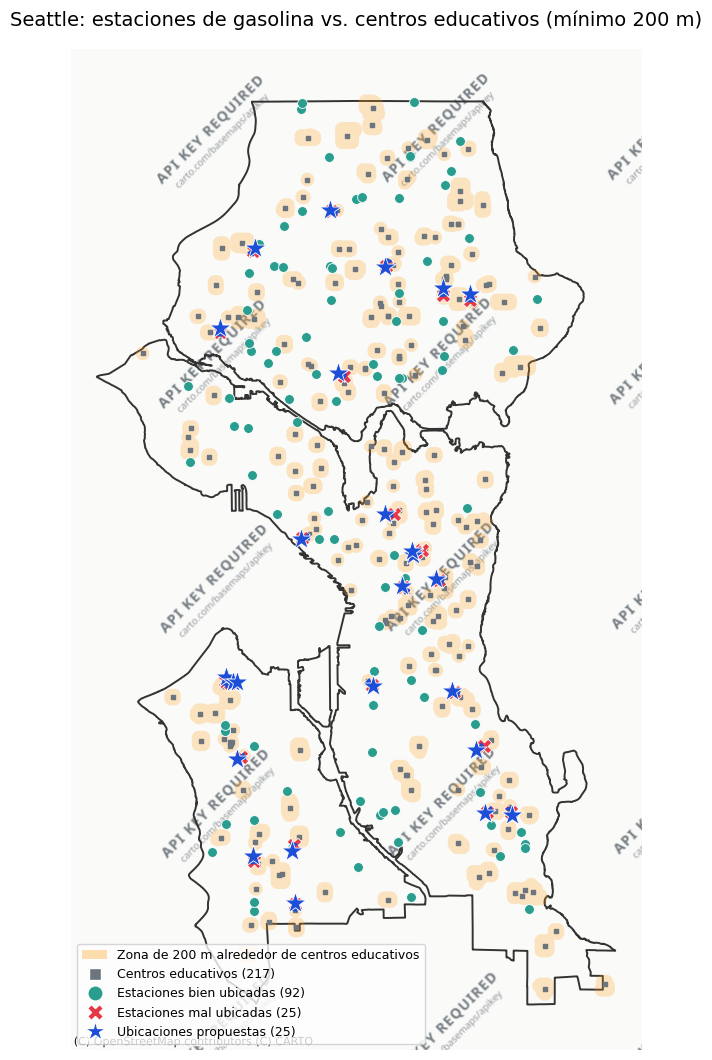


### Mapa interactivo

El mismo resultado en un mapa con zoom; las capas se pueden activar/desactivar arriba a la derecha.



## Resultado



- Centros educativos analizados: **217**
- Estaciones de gasolina en Seattle: **117**
- Estaciones **bien ubicadas** (≥ 200 m de un centro educativo): **92**
- Estaciones **mal ubicadas** (< 200 m): **25**
- Reubicaciones propuestas: **25**, con un desplazamiento mediano de **109 m** y máximo de **282 m**
- Todas las ubicaciones propuestas quedan a **200 m o más** de cualquier centro educativo.


In [5]:
from IPython.display import display, Markdown

display(Markdown(r"""
# Tarea Individual 2 – Estaciones de servicio vs. centros educativos en Seattle (WA, USA)

**Autor:** Romero Castillejo  |  **Datos:** [GitHub](https://github.com/Romero-Luis21/TareaIndividual2_Romero_Castillejo)

Flujo de trabajo:

1. Disolver los límites censales → límite único de Seattle.
2. Ubicar los centros educativos (OpenStreetMap).
3. Ubicar las estaciones de gasolina (OpenStreetMap).
4. Identificar qué estaciones están a **menos de 200 m** de algún centro educativo (mal ubicadas).
5. Proponer una reubicación para cada estación mal ubicada.
6. Graficar: bien ubicadas, mal ubicadas y ubicaciones propuestas.

> **Criterio usado:** una estación está *mal ubicada* si la distancia a su centro educativo más cercano es **menor a 200 m**
> (la regla es "distancia mínima de 200 m"). Todas las distancias se calculan en **metros** (EPSG:32610, UTM 10N),
> porque el shapefile original de Seattle suele venir en pies.
"""))

display(Markdown(r"""
## 0. Instalaciones, librerías y parámetros
"""))

!pip install -q osmnx contextily mapclassify

import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import contextily as cx
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ---------- DATOS EN GITHUB ----------
RAW     = "https://raw.githubusercontent.com/Romero-Luis21/TareaIndividual2_Romero_Castillejo/main/"
URL_ZIP = RAW + "2020_Census_Tracts_Seattle_8661193084158732132.zip"

# ---------- PARÁMETROS ----------
CRS_M    = "EPSG:32610"   # UTM 10N (metros) -> Seattle
MIN_DIST = 200            # distancia mínima estación - centro educativo (m)
MARGEN   = 10             # margen extra para las ubicaciones propuestas (m)
SEP_MIN  = 100            # separación mínima entre estaciones propuestas / existentes (m)
PASO_M   = 25             # cada cuántos metros se toma un punto candidato sobre las vías
EDU      = ["school"]     # amenity de OSM. Puedes agregar "kindergarten", "college", "university"



def unir(gs):
    """Unión de una GeoSeries (compatible con geopandas 0.x y 1.x)."""
    return gs.union_all() if hasattr(gs, "union_all") else gs.unary_union

display(Markdown(r"""
## 1. Disolver los límites censales → límite de Seattle

Se leen los *Census Tracts 2020* desde tu GitHub, se pasan a **metros** y se unen (`dissolve`) en **un solo polígono**
que representa a Seattle. Ese polígono será el área de trabajo para todo lo demás.
"""))

tractos = gpd.read_file(URL_ZIP)
tractos = tractos.to_crs(CRS_M)                 # a metros
tractos["geometry"] = tractos.geometry.buffer(0)  # repara geometrías inválidas

# --- DISOLVER: todos los tractos -> una sola geometría
seattle = tractos[["geometry"]].dissolve().reset_index(drop=True)
area_km2 = seattle.area.iloc[0] / 1e6
print(f"Área del límite disuelto: {area_km2:,.1f} km²")

# Seguridad: Seattle tiene ~217 km² (agua incluida). Si el archivo trae más (p. ej. todo King County),
# se recorta con el límite administrativo de Seattle de OSM.
if area_km2 > 400:
    limite = ox.geocode_to_gdf("Seattle, Washington, USA").to_crs(CRS_M)
    seattle = gpd.overlay(seattle, limite[["geometry"]], how="intersection")

seattle_geom = unir(seattle.geometry)
if hasattr(shapely, "prepare"):
    shapely.prepare(seattle_geom)               # acelera las pruebas punto-en-polígono

# Polígono simple (casco convexo) en lat/lon para consultar OSM; luego se recorta con el límite exacto
hull_ll = unir(seattle.to_crs(4326).geometry).convex_hull

print("\nTabla del límite disuelto (una sola geometría):")
display(seattle)
print("\nCRS de trabajo:")
print(repr(seattle.crs))

ax = seattle.plot(figsize=(6, 7), color="#cfe3f5", edgecolor="#1f4e79")
ax.set_title("Seattle: límites censales disueltos")
ax.set_axis_off()
plt.show()

display(Markdown(r"""
## 2. Ubicar los centros educativos de Seattle

Se descargan de OpenStreetMap (`amenity=school`) y se conservan solo los que caen dentro del límite de Seattle.
A continuación, cuántos son y una muestra de la tabla:
"""))

raw = ox.features_from_polygon(hull_ll, tags={"amenity": EDU})
nombre = raw.get("name", pd.Series(np.nan, index=raw.index))
escuelas = gpd.GeoDataFrame(
    {"escuela": nombre.fillna("Sin nombre").values,
     "element": raw.index.get_level_values(0).to_numpy()},   # node / way / relation
    geometry=raw.geometry.values, crs=raw.crs,
).to_crs(CRS_M)
escuelas = escuelas[~escuelas.is_empty & escuelas.intersects(seattle_geom)].reset_index(drop=True)

escuelas.info()
print("\nTipo de elemento OSM (node/way/relation) vs. tipo de geometría:")
display(pd.crosstab(escuelas["element"], escuelas.geom_type, margins=True))
print("Primeras filas:")
display(escuelas.head())

display(Markdown(r"""
## 3. Ubicar las estaciones de gasolina

Se descargan de OpenStreetMap (`amenity=fuel`), se filtran a Seattle y se unifican las que OSM dibujó dos veces
(como punto y como polígono). Resultado:
"""))

raw = ox.features_from_polygon(hull_ll, tags={"amenity": "fuel"})
nombre = raw.get("name", pd.Series(np.nan, index=raw.index))
marca  = raw.get("brand", pd.Series(np.nan, index=raw.index))
gas = gpd.GeoDataFrame(
    {"estacion": nombre.fillna(marca).fillna("Sin nombre").values,
     "element": raw.index.get_level_values(0).to_numpy()},   # node / way / relation
    geometry=raw.geometry.values, crs=raw.crs,
).to_crs(CRS_M)
gas = gas[~gas.is_empty & gas.intersects(seattle_geom)].reset_index(drop=True)
n_osm = len(gas)

# OSM a veces mapea la MISMA estación como punto y como polígono:
# se unifican las que se tocan (buffer de 15 m) y se conserva una por grupo (preferencia: polígono).
comp = gpd.GeoSeries(unir(gas.buffer(15)), crs=CRS_M).explode(index_parts=False).reset_index(drop=True)
grupos = gpd.GeoDataFrame({"grupo": comp.index}, geometry=comp.values, crs=CRS_M)
gas = gpd.sjoin(gas, grupos, how="left", predicate="intersects").drop(columns="index_right")
gas["es_poligono"] = gas.geom_type.str.contains("Polygon")
gas = (gas.sort_values("es_poligono", ascending=False)
          .drop_duplicates("grupo")
          .drop(columns=["grupo", "es_poligono"])
          .sort_index().reset_index(drop=True))
print(f"Estaciones en OSM: {n_osm} -> tras unificar duplicados: {len(gas)}")

gas["id"] = gas.index
gas.info()
print("\nTipo de elemento OSM (node/way/relation) vs. tipo de geometría:")
display(pd.crosstab(gas["element"], gas.geom_type, margins=True))
print("Primeras filas:")
display(gas.head())

display(Markdown(r"""
## 4. Estaciones a menos de 200 m de algún centro educativo (mal ubicadas)

Se hace en cuatro pasos, igual que en clase:

1. **Matriz de distancias** (en metros) entre cada estación y cada centro educativo.
2. **Distancia mínima** de cada estación a un centro educativo (se muestran las 10 más cercanas).
3. **Clasificación**: bien ubicada (≥ 200 m) o mal ubicada (< 200 m).
4. **Verificación con buffer + `sjoin`**: se crea una zona de seguridad de 200 m alrededor de cada centro educativo
   y se buscan las estaciones que la intersectan.
"""))

# ---- 4.1 Matriz de distancias estación -> centro educativo (metros)
etq_gas = gas.index.astype(str) + "_" + gas["estacion"]          # nombres únicos: 0_Shell, 1_Chevron...
etq_esc = escuelas.index.astype(str) + "_" + escuelas["escuela"]
D_gas_escuela = pd.DataFrame(
    [escuelas.distance(g).values for g in gas.geometry],
    index=etq_gas, columns=etq_esc,
)
print("Matriz de distancias (m): filas = estaciones, columnas = centros educativos")
display(D_gas_escuela.round(1))

# ---- 4.2 Distancia mínima de cada estación a un centro educativo
print("\nLas 10 estaciones más cercanas a un centro educativo (m):")
display(D_gas_escuela.min(axis=1).sort_values().head(10).round(1))

# ---- 4.3 Clasificación
cerca = gpd.sjoin_nearest(gas, escuelas[["escuela", "geometry"]], how="left", distance_col="dist_escuela_m")
cerca = cerca[~cerca.index.duplicated(keep="first")]      # por si hay empates

gas["escuela_cercana"] = cerca["escuela"]
gas["dist_escuela_m"]  = cerca["dist_escuela_m"].round(1)
gas["bien_ubicada"]    = gas["dist_escuela_m"] >= MIN_DIST

print(gas["bien_ubicada"].value_counts().rename(
    {True: f"Bien ubicadas (>= {MIN_DIST} m)", False: f"Mal ubicadas (< {MIN_DIST} m)"}))

print("\nEstaciones MAL ubicadas:")
display(gas.loc[~gas["bien_ubicada"], ["id", "estacion", "escuela_cercana", "dist_escuela_m"]]
          .sort_values("dist_escuela_m").reset_index(drop=True))

# ---- 4.4 Verificación: zonas de seguridad (buffer) + sjoin con "intersects"
escuelas_buf = gpd.GeoDataFrame({"escuela": escuelas["escuela"]},
                                geometry=escuelas.buffer(MIN_DIST), crs=CRS_M)
print(f"Zonas de seguridad: buffer de {MIN_DIST} m alrededor de cada centro educativo")
display(escuelas_buf.head())

gas_relocar = gas.sjoin(escuelas_buf, how="inner", predicate="intersects")
print("\nEstaciones que intersectan una zona de seguridad (una fila por cada centro educativo cercano):")
display(gas_relocar[["id", "estacion", "escuela", "dist_escuela_m"]]
          .rename(columns={"escuela": "zona_de_escuela"}).sort_values("dist_escuela_m"))

print("Estaciones distintas con buffer + sjoin :", gas_relocar["id"].nunique())
print("Estaciones mal ubicadas por distancia   :", int((~gas["bien_ubicada"]).sum()))

display(Markdown(r"""
## 5. Propuesta de reubicación

Para cada estación mal ubicada se busca el **sitio candidato más cercano** que cumpla:

- está dentro de Seattle y sobre una **vía principal** (trunk / primary / secondary / tertiary de OSM), para que sea un lugar realista;
- está a **≥ 200 m (+ margen)** de todo centro educativo;
- está a **≥ 100 m** de las estaciones que se quedan y de las demás ubicaciones propuestas (evita amontonarlas).
"""))

# ---- 5.1 Vías principales (donde tiene sentido poner una estación)
raw = ox.features_from_polygon(hull_ll, tags={"highway": ["trunk", "primary", "secondary", "tertiary"]})
raw = raw[raw.geom_type.isin(["LineString", "MultiLineString"])]
vias = raw[["highway", "geometry"]].to_crs(CRS_M)
vias = vias[vias.intersects(seattle_geom)].reset_index(drop=True)

# ---- 5.2 Puntos candidatos cada PASO_M metros sobre esas vías
lineas = vias.geometry.explode(index_parts=False)
pts = [ln.interpolate(d) for ln in lineas for d in np.arange(0, ln.length, PASO_M)]
cand = gpd.GeoDataFrame(geometry=pts, crs=CRS_M)
cand = cand[cand.within(seattle_geom)].reset_index(drop=True)

# ---- 5.3 Solo candidatos a >= MIN_DIST + MARGEN de cualquier centro educativo
d_esc = gpd.sjoin_nearest(cand, escuelas[["geometry"]], how="left", distance_col="d_escuela")
d_esc = d_esc[~d_esc.index.duplicated(keep="first")]
cand = cand[d_esc["d_escuela"] >= MIN_DIST + MARGEN].reset_index(drop=True)

# ---- 5.4 Asignación: cada estación mal ubicada -> candidato válido más cercano
buenas = gas[gas["bien_ubicada"]]
malas  = gas[~gas["bien_ubicada"]]

# Puntos que "bloquean" (estaciones que se quedan); se irán sumando las propuestas
bloq = np.array([[p.x, p.y] for p in buenas.representative_point()]).reshape(-1, 2)
cx_, cy_ = cand.geometry.x.values, cand.geometry.y.values

filas = []
for idx, est in malas.sort_values("dist_escuela_m").iterrows():
    p = est["geometry"].representative_point()
    d_orig = np.hypot(cx_ - p.x, cy_ - p.y)           # distancia estación actual -> cada candidato
    orden = np.argsort(d_orig)                        # del más cercano al más lejano

    elegido = orden[0]                                # (por defecto el más cercano)
    for j in orden:                                   # el primero que respete la separación mínima
        if len(bloq) == 0 or np.hypot(bloq[:, 0] - cx_[j], bloq[:, 1] - cy_[j]).min() >= SEP_MIN:
            elegido = j
            break

    bloq = np.vstack([bloq, [cx_[elegido], cy_[elegido]]])
    filas.append({
        "id": int(est["id"]),
        "estacion": est["estacion"],
        "escuela_cercana": est["escuela_cercana"],
        "dist_escuela_actual_m": est["dist_escuela_m"],
        "mover_m": round(float(d_orig[elegido]), 0),
        "geometry": cand.geometry.iloc[elegido],
    })

reubicaciones = gpd.GeoDataFrame(filas, geometry="geometry", crs=CRS_M)

# ---- 5.5 Verificación: toda ubicación propuesta debe quedar a >= 200 m de un centro educativo
chk = gpd.sjoin_nearest(reubicaciones[["geometry"]], escuelas[["geometry"]], how="left", distance_col="d")
chk = chk[~chk.index.duplicated(keep="first")]
reubicaciones["dist_escuela_nueva_m"] = chk["d"].round(1)
assert (reubicaciones["dist_escuela_nueva_m"] >= MIN_DIST).all(), "Alguna propuesta no cumple la distancia mínima"

print(f"{len(reubicaciones)} reubicaciones propuestas. Todas cumplen >= {MIN_DIST} m.\n")
display(reubicaciones)

display(Markdown(r"""
## 6. Gráfica final: bien ubicadas, mal ubicadas y ubicaciones propuestas

**Mapa estático:** el área naranja es la zona de 200 m alrededor de cada centro educativo; las estaciones en **verde**
están bien ubicadas, las **X rojas** están dentro de esa zona, y las **estrellas azules** son las ubicaciones propuestas
(la flecha une cada estación actual con su nueva ubicación).
"""))

# Las estaciones pueden ser polígonos: para dibujarlas se usa un punto representativo
gas_pts   = gas.set_geometry(gas.representative_point())
buenas_pt = gas_pts[gas_pts["bien_ubicada"]]
malas_pt  = gas_pts[~gas_pts["bien_ubicada"]]
n_ok, n_mal = len(buenas_pt), len(malas_pt)

fig, ax = plt.subplots(figsize=(11, 13))

seattle.plot(ax=ax, facecolor="none", edgecolor="#333333", linewidth=1.4, zorder=1)

# zona de exclusión (200 m) alrededor de los centros educativos
zona = gpd.GeoSeries(unir(escuelas.buffer(MIN_DIST)), crs=CRS_M)
zona.plot(ax=ax, color="#ff9f1c", alpha=0.25, zorder=2)

escuelas.representative_point().plot(ax=ax, color="#6c757d", marker="s", markersize=10, zorder=3)
buenas_pt.plot(ax=ax, color="#2a9d8f", markersize=50, edgecolor="white", linewidth=0.6, zorder=4)
malas_pt.plot(ax=ax, color="#e63946", marker="X", markersize=110, edgecolor="white", linewidth=0.6, zorder=5)
reubicaciones.plot(ax=ax, color="#1d4ed8", marker="*", markersize=260, edgecolor="white", linewidth=0.6, zorder=6)

# flechas: estación actual -> ubicación propuesta
for _, r in reubicaciones.iterrows():
    o = gas_pts.geometry.loc[r["id"]]
    d = r["geometry"]
    ax.annotate("", xy=(d.x, d.y), xytext=(o.x, o.y), zorder=5,
                arrowprops=dict(arrowstyle="-|>", color="#1d4ed8", lw=1.3, shrinkA=4, shrinkB=4))

leyenda = [
    mpatches.Patch(facecolor="#ff9f1c", alpha=0.35, label=f"Zona de {MIN_DIST} m alrededor de centros educativos"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#6c757d", markersize=8,  label=f"Centros educativos ({len(escuelas)})"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#2a9d8f", markersize=11, label=f"Estaciones bien ubicadas ({n_ok})"),
    Line2D([0], [0], marker="X", color="w", markerfacecolor="#e63946", markersize=12, label=f"Estaciones mal ubicadas ({n_mal})"),
    Line2D([0], [0], marker="*", color="w", markerfacecolor="#1d4ed8", markersize=16, label=f"Ubicaciones propuestas ({len(reubicaciones)})"),
]
ax.legend(handles=leyenda, loc="lower left", frameon=True, fontsize=9)
ax.set_title(f"Seattle: estaciones de gasolina vs. centros educativos (mínimo {MIN_DIST} m)", fontsize=14)
ax.set_axis_off()

try:
    cx.add_basemap(ax, crs=CRS_M, source=cx.providers.CartoDB.Positron)
except Exception:
    pass          # si no hay conexión a los mosaicos, el mapa se dibuja igual, sin fondo

plt.show()

display(Markdown(r"""
### Mapa interactivo

El mismo resultado en un mapa con zoom; las capas se pueden activar/desactivar arriba a la derecha.
"""))

# Mapa interactivo (opcional, como en las clases)
import folium

m = seattle.explore(tiles="cartodbpositron", name="Seattle",
                    style_kwds={"fill": False, "color": "black", "weight": 2})
escuelas[["escuela", "geometry"]].explore(m=m, name="Centros educativos", color="gray",
                                          style_kwds={"fillOpacity": 0.5})
buenas_pt[["estacion", "dist_escuela_m", "escuela_cercana", "geometry"]].explore(
    m=m, name="Bien ubicadas", color="green", marker_kwds={"radius": 6})
malas_pt[["estacion", "dist_escuela_m", "escuela_cercana", "geometry"]].explore(
    m=m, name="Mal ubicadas", color="red", marker_kwds={"radius": 7})
reubicaciones[["estacion", "mover_m", "dist_escuela_nueva_m", "geometry"]].explore(
    m=m, name="Ubicaciones propuestas", color="blue", marker_kwds={"radius": 9})
folium.LayerControl().add_to(m)
display(m)

display(Markdown(r"""
## Resultado
"""))

mov = reubicaciones["mover_m"]
display(Markdown(f"""
- Centros educativos analizados: **{len(escuelas)}**
- Estaciones de gasolina en Seattle: **{len(gas)}**
- Estaciones **bien ubicadas** (≥ {MIN_DIST} m de un centro educativo): **{n_ok}**
- Estaciones **mal ubicadas** (< {MIN_DIST} m): **{n_mal}**
- Reubicaciones propuestas: **{len(reubicaciones)}**, con un desplazamiento mediano de **{mov.median():,.0f} m** y máximo de **{mov.max():,.0f} m**
- Todas las ubicaciones propuestas quedan a **{MIN_DIST} m o más** de cualquier centro educativo.
"""))
